# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'benh7'   # <-- set this
d = np.genfromtxt(f'../../labs/07/data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

255 epochs over 965 days; median quoted error 0.041 mag; rms of the light curve 0.172 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


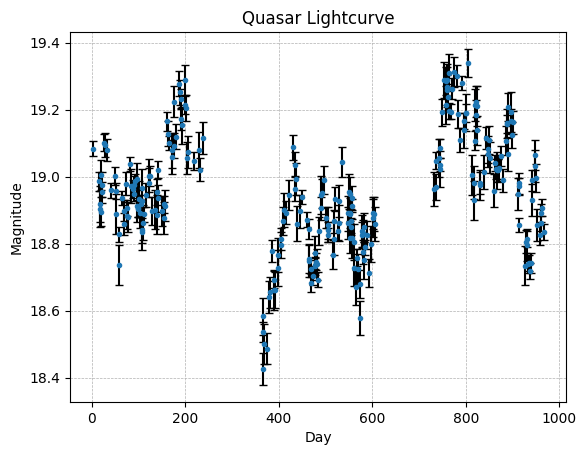

In [370]:
# Part 1: your work here
plt.errorbar(t, y, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.title('Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)

In [371]:
T = np.max(t) - np.min(t)
maxfreq = (1 / 20)
minfreq = (1 / (.5 * T) )

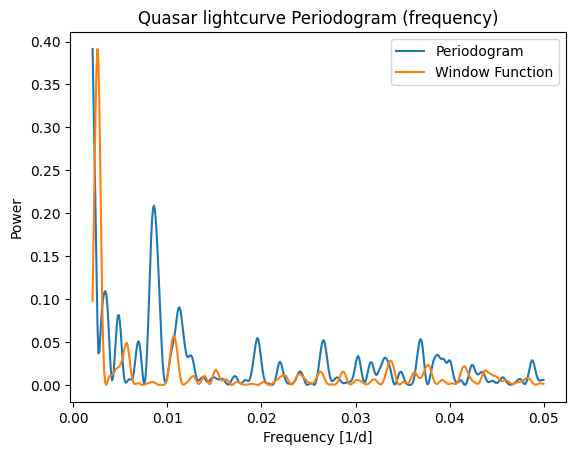

In [372]:
ls = LombScargle(t, y, dy = e)
frequency, power = ls.autopower(minimum_frequency = minfreq, maximum_frequency = maxfreq, samples_per_peak = 10)
frequency_wf, power_wf = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).autopower(minimum_frequency = minfreq, maximum_frequency = maxfreq, samples_per_peak = 10)

power_max = np.max(power)
power_wf_max = np.max(power_wf)
scaling_ratio = power_max / power_wf_max

power_wf = power_wf * scaling_ratio

plt.plot(frequency, power, label = 'Periodogram')
plt.plot(frequency_wf, power_wf, label = 'Window Function')

plt.title('Quasar lightcurve Periodogram (frequency)')
plt.xlabel('Frequency [1/d]')
plt.ylabel('Power')
plt.legend()

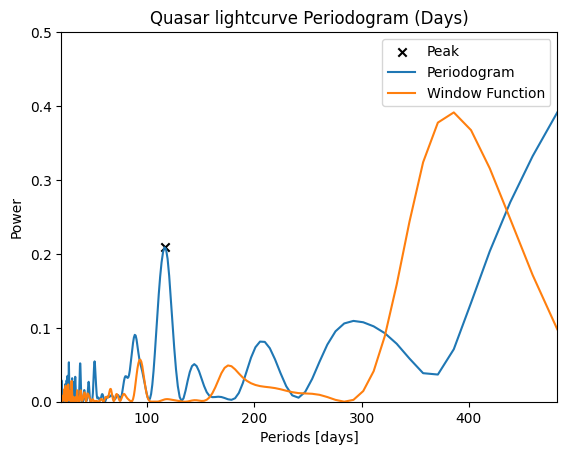

In [373]:
periods = 1 / frequency
periods_wf = 1 / frequency_wf

left_shifted = np.roll(power, 1)
right_shifted = np.roll(power, -1)

peak_mask = (power > left_shifted) & (power > right_shifted)
peak_indices = np.where(peak_mask)[0]

true_peak = np.argmax(power[peak_indices][1:])

plt.scatter(periods[peak_indices][true_peak + 1], power[peak_indices][true_peak + 1], color = 'black', marker = 'x', label = 'Peak')

plt.plot(periods, power, label = 'Periodogram')
plt.plot(periods_wf, power_wf, label = 'Window Function')
plt.title('Quasar lightcurve Periodogram (Days)')
plt.xlabel('Periods [days]')
plt.ylabel('Power')
plt.xlim([20, T/2])
plt.ylim([0, .5])
plt.legend()

In [374]:
print(periods[peak_indices][true_peak + 1])
print(periods[peak_indices])

116.2322891566265
[482.364      292.34181818 205.2612766  166.33241379 143.98925373
 116.23228916  88.50715596  80.394       72.53593985  66.995
  63.05411765  58.11614458  54.50440678  51.04380952  48.2364
  45.50603774  41.40463519  39.53803279  37.53805447  35.59881919
  33.03863014  31.63042623  30.14775     28.71214286  27.09910112
  25.86402145  25.45456464  24.99295337  24.3004534   23.58748166
  23.02453461  22.43553488  21.92563636  21.06393013  20.52612766
  20.05671518]


In [375]:
flsalrm = ls.false_alarm_probability(power[peak_indices][true_peak + 1])
print(flsalrm)

6.540762253050354e-10


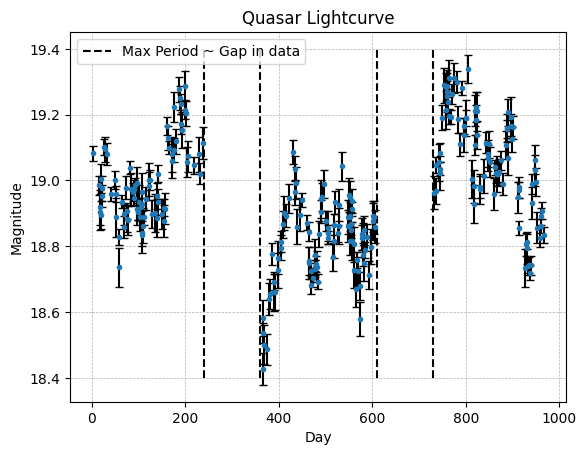

In [307]:
plt.errorbar(t, y, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.title('Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)

plt.vlines(610, ymin = 18.4, ymax = 19.4, color = 'black', linestyle = '--', label = 'Max Period ~ Gap in data')
plt.vlines(730, ymin = 18.4, ymax = 19.4, color = 'black', linestyle = '--')

plt.vlines(240, ymin = 18.4, ymax = 19.4, color = 'black', linestyle = '--')
plt.vlines(360, ymin = 18.4, ymax = 19.4, color = 'black', linestyle = '--')

plt.legend()

**ANSWER (a few sentences):**

*The highest peak has a period of about 116.23 days. The period of 58.116 days is likely an alias of this period as it 1/2 of the period of 116.23 days. Rather than searching for every peak, the search space is limited to T/2. Any periods larger than this would not result in a periodic structure within the data (as it lasts longer than half the data to repeat). This means there isn't enough information to conclude anything about the legitimaticy of this periodicty. As these peaks aren't worth investigating, the search is limited to periods that can repeat within the length of the given data. Astropy's false alarm probability assumes that there is no periodic signal within the data. This false alarm probability is the probability that a peak this size will be observed that there is no signal whatsoever. However, since the observed gap is just about the same size as the observed period, the periodogram is likely finding the idduced period in the data created by the gaps in observation.*

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


In [10]:
# Part 2: your work here
def log_likelihood(theta, t, y, e):

    mu, ln_sigma, ln_tau = theta

    sigma = np.exp(ln_sigma)
    tau = np.exp(ln_tau)

    dt = np.abs(t[:, None] - t[None, :])

    C = (sigma**2 * np.exp(-dt / tau) + np.diag(e**2) )

    residuals = y - mu

    cho = cho_factor(C)

    alpha = cho_solve(cho, residuals)

    logdet = 2 * np.sum( np.log(np.diag(cho[0])) )

    n = len(y)

    return ( -0.5 * residuals @ alpha -0.5 * logdet -0.5 * n * np.log(2*np.pi) )

def log_prior(theta):

    mu, ln_sigma, ln_tau = theta

    sigma = np.exp(ln_sigma)
    tau = np.exp(ln_tau)

    if (sigma < 0.01) | (3 < sigma):
        return -np.inf

    if (tau < 10) | (4000 < tau):
        return -np.inf

    return 0.0

def log_posterior(theta, t, y, e):

    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(theta, t, y, e)

PRIORS:

1) 0.01 < sigma < 3 : Prevents the root mean square variability from being less than .01 or greater than 3. The trusted errors are about ~.025. Having a variability lower than .01 would result in an RMS variability less than half the known variability. This is a significantly lower variability than would be expected. Conversely, a variability greater than 3 would result in a variability more than a couple orders of magnitude. This would be unrealistic and result in extreamly large variations.
2) 10 < tau < 4000 d : This is a fairly uniformitive prior; There are only ~960 days of data provided. A tau of 4000 would be a damping about 4 times larger than the there is data to observe over. A damping time of 10, is very small; would allow for signal to incorperate multiple (~96) independent samples

This bound on tau limits the search for a tau within the data rather than searching all possible correlation times.

In [11]:
from scipy.optimize import minimize

sigma_start = np.linspace(.05, 2.5, 30)
tau_start = np.linspace(50, 4950, 30)

start = []

for i in range(30):
    for j in range(30):
        start.append([np.mean(y), np.log(sigma_start[i]), np.log(tau_start[j]) ] )

results = []
liklihoods = []

for s in start:

    result = minimize(
        lambda theta: -log_likelihood(theta, t, y, e), s)

    results.append(result.x)
    liklihoods.append(-result.fun)

In [12]:
liklihoods = np.array(liklihoods)
idx = np.argmax(liklihoods)

print(liklihoods[idx])
print(results[idx])

310.769389871818
[18.94957414 -1.79489864  3.70924307]


In [13]:
print(np.exp(-1.79489864))
print(np.exp(3.70924307))

0.166144291878816
40.82289475571519


In [14]:
theta = np.array(results[idx])

pos = theta + 1e-1 * np.random.randn(64, 3)

nwalkers, ndim = pos.shape

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_posterior, args=(t, y, e)
)

sampler.run_mcmc(pos, 20_000, progress = False)
print('')

Mean acceptance fraction: 0.61 (0.2-0.5 is healthy)


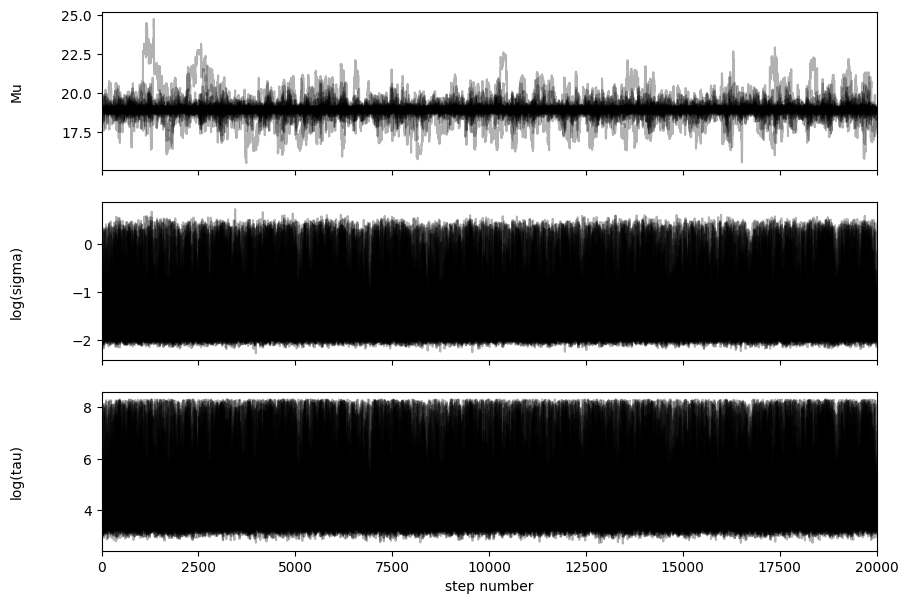

In [15]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["Mu", "log(sigma)", "log(tau)"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

print(f"Mean acceptance fraction: {sampler.acceptance_fraction.mean():.2f} (0.2-0.5 is healthy)")

In [16]:
tau = sampler.get_autocorr_time()
print(tau)

[106.10831208  81.73654861  81.73061184]


In [17]:
tau_max = np.max(tau)
print(tau_max)

106.10831207814836


In [18]:
tau_max = 70

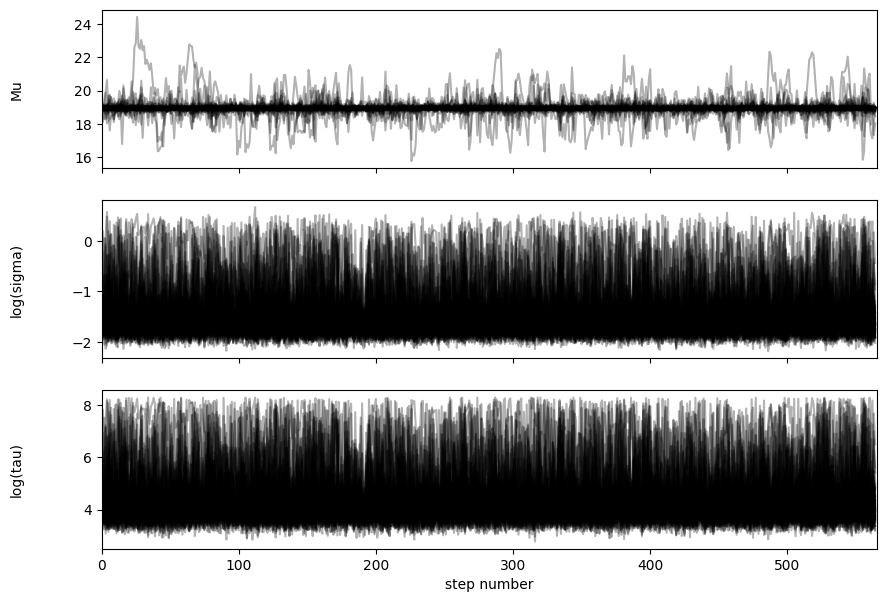

In [19]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
modified_samples = sampler.get_chain(discard = 210, thin = 35)
for i in range(ndim):
    ax = axes[i]
    ax.plot(modified_samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(modified_samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

In [20]:
!pip install pymc arviz

In [21]:
import arviz as az

idata = az.from_dict({'posterior' : {
        "Mu": samples[:, :, 0].T,
        "log(sigma)": samples[:, :, 1].T,
        "log(tau)": samples[:, :, 2].T,
    }}
)

In [22]:
az.summary(idata)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Mu,18.953,0.25,19,19,18347,24185,1.00,0.0029,0.012
log(sigma),-1.52,0.444,-1.9,-0.57,18480,19742,1.00,0.0037,0.0049
log(tau),4.28,0.92,3.4,6.2,17998,20009,1.00,0.0077,0.0099


Checking for convergence: All three paramaters are less than 1.01 R_hat. This indicates convergence. Additionally, all the parameters have more than 15,000 effective samples and there are many more samples than an autocorrelation time of 50tau indicating that there are enough independent samples. 

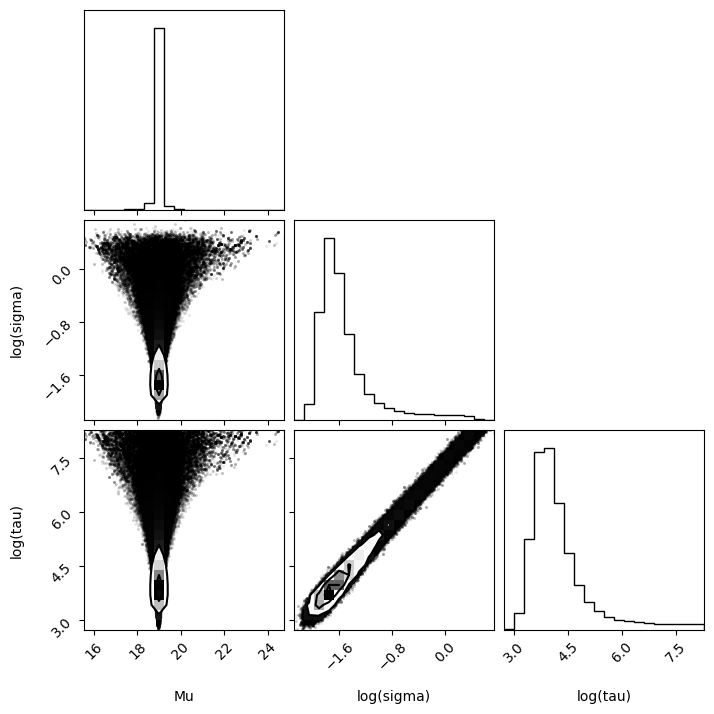

In [23]:
import corner
flat_samples = sampler.get_chain(discard = 210, flat = True)

MCMCMu = flat_samples.T[0]
MCMClogSigma = flat_samples.T[1]
MCMClogTau = flat_samples.T[2]

MCMC = np.array([MCMCMu, MCMClogSigma, MCMClogTau])

labels2 = ["Mu", "log(sigma)", "log(tau)"]

fig = corner.corner(MCMC.T, labels=labels2)

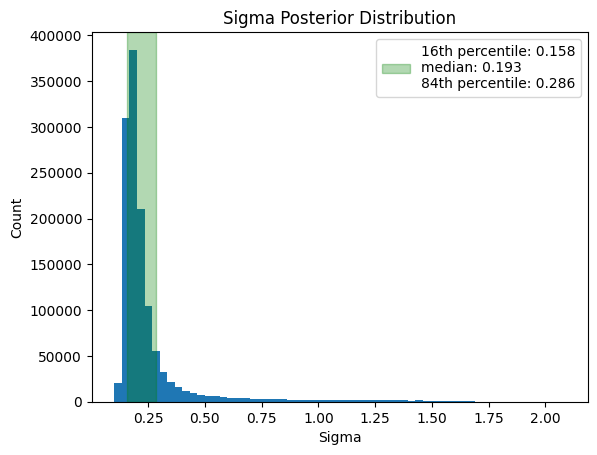

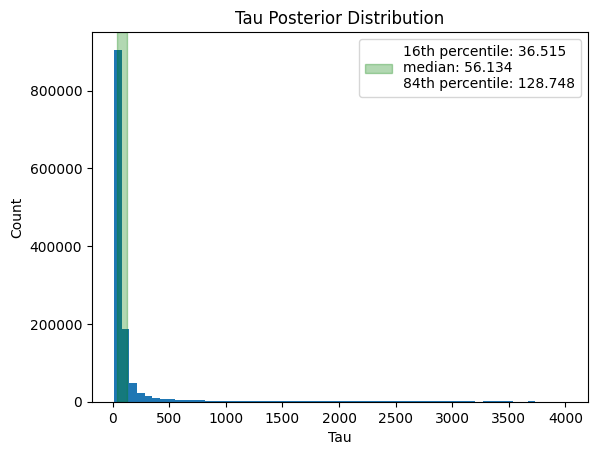

In [25]:
MCMCSigma = np.exp(MCMClogSigma)
MCMCTau = np.exp(MCMClogTau)

plt.figure(1)
plt.hist(MCMCSigma, bins = 60)
plt.title('Sigma Posterior Distribution')
plt.xlabel('Sigma')
plt.ylabel('Count')

lo_sigma, med_sigma, hi_sigma = np.percentile(MCMCSigma, [16, 50, 84])
plt.axvspan(lo_sigma, hi_sigma, color = 'green', alpha = .3, label = f'16th percentile: {lo_sigma:.3f}\nmedian: {med_sigma:.3f}\n84th percentile: {hi_sigma:.3f}')

plt.legend()

plt.figure(2)
plt.hist(MCMCTau, bins = 60)
plt.title('Tau Posterior Distribution')
plt.xlabel('Tau')
plt.ylabel('Count')

lo_tau, med_tau, hi_tau = np.percentile(MCMCTau, [16, 50, 84])
plt.axvspan(lo_tau, hi_tau, color = 'green', alpha = .3, label = f'16th percentile: {lo_tau:.3f}\nmedian: {med_tau:.3f}\n84th percentile: {hi_tau:.3f}')

plt.legend()

In [259]:
print(f'Sigma: {med_sigma:.3f} +({(hi_sigma - med_sigma):.3f}) or -({(med_sigma - lo_sigma):.3f})')
print(f'Tau: {med_tau:.3f} +({(hi_tau - med_tau):.3f}) or -({(med_tau - lo_tau):.3f})')
print(f'T/tau : {(T / med_tau):.3f}')

th = [np.median(MCMCMu), np.log(med_sigma), np.log(med_tau)]
print(f'Final Likelihood: {log_likelihood(th, t, y, e):.3f}')

Sigma: 0.193 +(0.093) or -(0.035)
Tau: 56.134 +(72.614) or -(19.619)
T/tau : 17.186
Final Likelihood: 310.411


Tau is hard to measure as it is strongly correlated with sigma. As sigma increases, tau increases as well. This correlation causes the variables to shift together as values are being searched. Additionally, as tau increases, the length of the correlation increases. This allows for a number of possible correlation timescales creating a tail in the data leading to very wide asymetric uncertainties. 

In [27]:
def log_likelihood_se(theta, t, y, e):

    mu, ln_sigma, ln_l = theta

    sigma = np.exp(ln_sigma)
    l = np.exp(ln_l)

    dt = np.abs(t[:, None] - t[None, :])

    C = (sigma**2 * np.exp(-(dt**2) / (2 * l**2)) + np.diag(e**2) )

    residuals = y - mu

    cho = cho_factor(C)

    alpha = cho_solve(cho, residuals)

    logdet = 2 * np.sum( np.log(np.diag(cho[0])) )

    n = len(y)

    return ( -0.5 * residuals @ alpha -0.5 * logdet -0.5 * n * np.log(2*np.pi) )

def log_prior_se(theta):

    mu, ln_sigma, ln_l = theta

    sigma = np.exp(ln_sigma)
    l = np.exp(ln_l)

    if (sigma < 0.01) | (3 < sigma):
        return -np.inf

    if (l < 10) | (4000 < l):
        return -np.inf

    return 0.0

def log_posterior_se(theta, t, y, e):

    lp = log_prior_se(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood_se(theta, t, y, e)

In [34]:
l_start = np.linspace(500, 4500, 30)

start2 = []

for i in range(30):
    for j in range(30):
        start2.append([np.mean(y), np.log(sigma_start[i]), np.log(l_start[j]) ] )

results2 = []
liklihoods2 = []

for s in start2:

    try:
        result = minimize(lambda theta: -log_likelihood_se(theta, t, y, e), s)

        results2.append(result.x)
        liklihoods2.append(-result.fun)

    except:
        continue

In [38]:
liklihoods2 = np.array(liklihoods2)
idx2 = np.argmax(liklihoods2)

print(liklihoods2[idx2])
print(results[idx2])

287.5679507900653
[18.94957416 -1.79489897  3.70924228]


In [39]:
print(f'DWR optimized likelihood: {liklihoods[idx]:.3f}')
print(f'Squared-Exponential optimized likelihood: {liklihoods2[idx2]:.3f}')

DWR optimized likelihood: 310.769
Squared-Exponential optimized likelihood: 287.568


My DRW had a higher liklihood by ~30. The DRW incorperates jagged motion rather than being a smooth line like the squared exponential. As my DRW likelihood is much larger than that of the squared exponential model, the DRW model is a more favorable model. This indicates that the quasar data is not very smooth as the more jagged model is favored.

In [316]:
med_mu = np.median(MCMCMu)
t_pred = np.linspace(0, 350, 1000)
t_mask = (t < 350)

dt2 = np.abs(t[t_mask][:, None] - t[t_mask][None, :])
C2 = med_sigma**2 * np.exp(-dt2 / med_tau) + np.diag(e[t_mask]**2)
Cho2 = cho_factor(C2)
residuals2 = y[t_mask] - med_mu
alpha2 = cho_solve(Cho2, residuals2)

dt_star = np.abs(t[t_mask][:, None] - t_pred[None, :])
K_star = med_sigma**2 * np.exp(-dt_star / med_tau)
mu_pred = med_mu + K_star.T @ alpha2

v = cho_solve(Cho2, K_star)
var_pred = med_sigma**2 - np.sum(K_star * v, axis = 0)

var_pred = np.maximum(var_pred, 0)

std_pred = np.sqrt(var_pred)
upper = mu_pred + std_pred
lower = mu_pred - std_pred


t_pred2 = np.linspace(0, T, 1000)
dt3 = np.abs(t[:, None] - t[None, :])
C3 = med_sigma**2 * np.exp(-dt3 / med_tau) + np.diag(e**2)
Cho3 = cho_factor(C3)
residuals3 = y - med_mu
alpha3 = cho_solve(Cho3, residuals3)

dt_star2 = np.abs(t[:, None] - t_pred2[None, :])
K_star2 = med_sigma**2 * np.exp(-dt_star2 / med_tau)
mu_pred2 = med_mu + K_star2.T @ alpha3

v2 = cho_solve(Cho3, K_star2)
var_pred2 = med_sigma**2 - np.sum(K_star2 * v2, axis = 0)

var_pred2 = np.maximum(var_pred2, 0)

std_pred2 = np.sqrt(var_pred2)
upper2 = mu_pred2 + std_pred2
lower2 = mu_pred2 - std_pred2

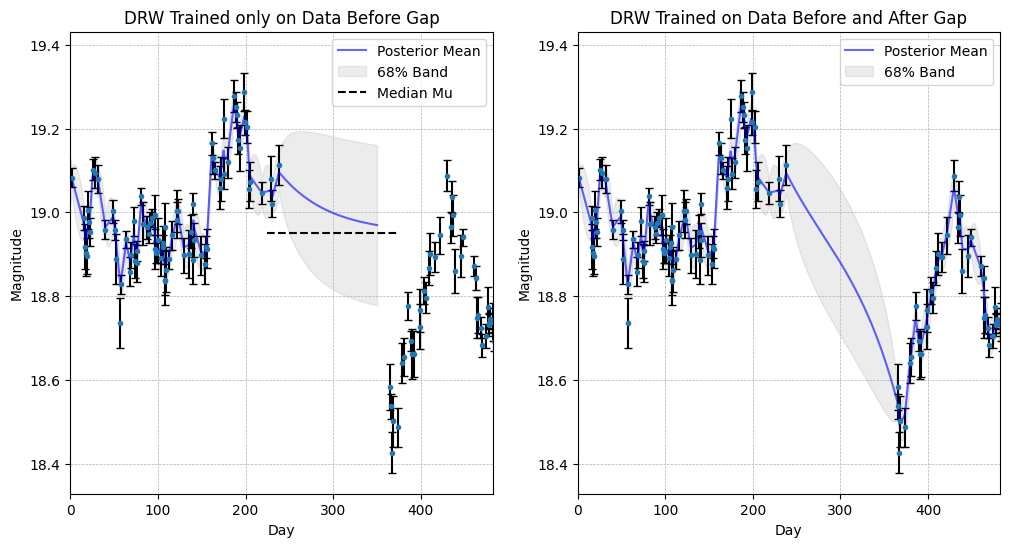

In [317]:
plt.figure(1, figsize = (12,6))

plt.subplot(1, 2, 1)
plt.errorbar(t, y, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.plot(t_pred, mu_pred, color = 'blue', alpha = .6, label = 'Posterior Mean')
plt.fill_between(t_pred, lower, upper, alpha = 0.15, color = 'grey', label = '68% Band')

plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.title('DRW Trained only on Data Before Gap')
plt.hlines(med_mu, xmin = 225, xmax = 375, color = 'black', linestyle = '--', label = 'Median Mu')

plt.xlim([0, T/2])
plt.grid(linestyle = '--', linewidth = 0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.errorbar(t, y, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.plot(t_pred2, mu_pred2, color = 'blue', alpha = .6, label = 'Posterior Mean')
plt.fill_between(t_pred2, lower2, upper2, alpha = 0.15, color = 'grey', label = '68% Band')

plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.title('DRW Trained on Data Before and After Gap')

plt.xlim([0, T/2])
plt.grid(linestyle = '--', linewidth = 0.5)
plt.legend()

This is for a latent lightcurve. The lightcurve band represents the uncertainty in the quasar brightness after modeling the DRW model. After fitting the model, the uncertainty only includes the changes in the quasar's brightness, not the observtional uncertianty as well. This means that the spread of the range will be smaller than the data points that are observed and may not include them. For new points, the uncertainty will grow as is now both observational and brightness uncertainty. When there is no further data, the best prediction becomes the sample mean. Due to this, the model will tend towards the sample mean.

In [233]:
rng = np.random.default_rng(seed = 10_272_026)

numbers = []
length = 0
inside = False
while length < 4:
    
    r = rng.integers(low = 0, high = 967)

    for n in numbers:
        if (n < r) & (r < (n + 30)):
            inside = True
        
        if np.abs(n - r) < 60:
            inside = True
    
    if (590 < r + 30) & (r < 750):
            inside = True
    if (230 < r + 30) & (r < 370):
            inside = True

    if inside == True:
        inside = False
        continue
    else:
        numbers.append(r)
        length = len(numbers)

In [234]:
numbers

[np.int64(453), np.int64(179), np.int64(106), np.int64(921)]

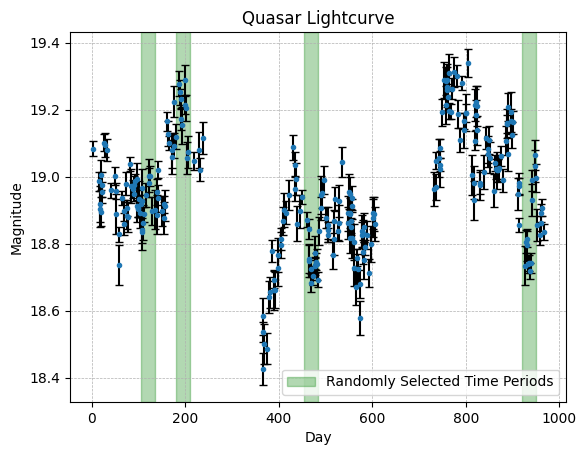

In [235]:
plt.errorbar(t, y, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.title('Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)

for rand in numbers:
    plt.axvspan(rand, rand + 30, color = 'green', alpha = .3)

plt.legend(['Randomly Selected Time Periods'])

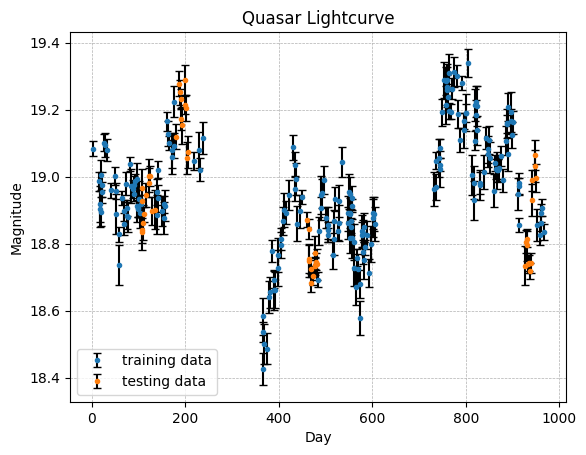

In [236]:
rand_mask = ((numbers[0] < t) & (t < numbers[0] + 30)) | ((numbers[1] < t) & (t < numbers[1] + 30)) | ((numbers[2] < t) & (t < numbers[2] + 30)) | ((numbers[3] < t) & (t < numbers[3] + 30))

plt.errorbar(t[~rand_mask], y[~rand_mask], yerr = e[~rand_mask], fmt = '.', ecolor = 'black', capsize = 3, label = 'training data')
plt.errorbar(t[rand_mask], y[rand_mask], yerr = e[rand_mask], fmt = '.', ecolor = 'black', capsize = 3, label = 'testing data')
plt.title('Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)
plt.legend()

In [237]:
dt4 = np.abs(t[~rand_mask][:, None] - t[~rand_mask][None, :])
C4 = med_sigma**2 * np.exp(-dt4 / med_tau) + np.diag(e[~rand_mask]**2)
Cho4 = cho_factor(C4)
residuals4 = y[~rand_mask] - med_mu
alpha4 = cho_solve(Cho4, residuals4)

dt_star3 = np.abs(t[~rand_mask][:, None] - t[rand_mask][None, :])
K_star3 = med_sigma**2 * np.exp(-dt_star3 / med_tau)
mu_pred3 = med_mu + K_star3.T @ alpha4

v3 = cho_solve(Cho4, K_star3)
var_pred3 = med_sigma**2 - np.sum(K_star3 * v3, axis = 0)

var_pred3 = np.maximum(var_pred3, 0)
std_pred3 = np.sqrt(var_pred3 + e[rand_mask]**2)

upper3 = mu_pred3 + std_pred3
lower3 = mu_pred3 - std_pred3

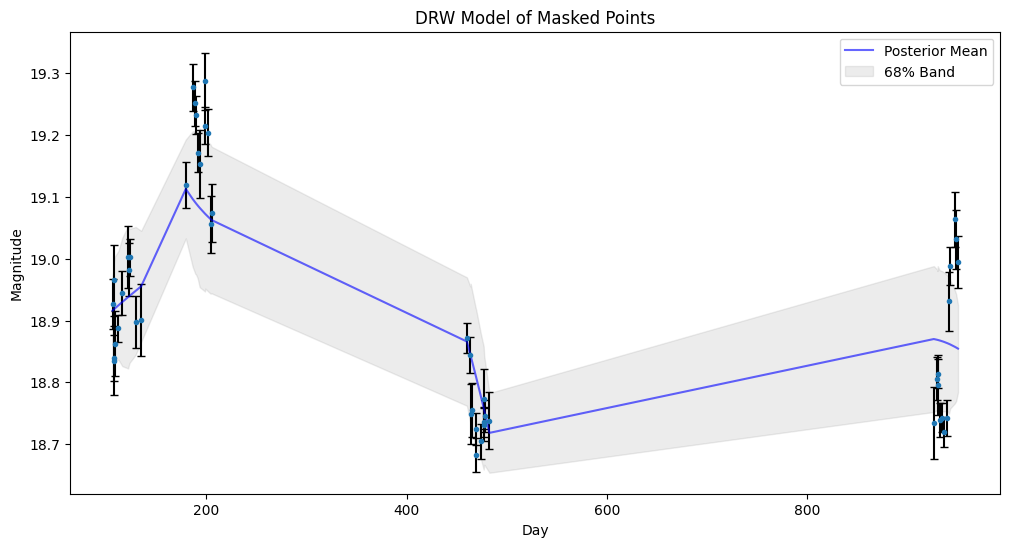

In [250]:
plt.figure(figsize = (12, 6)) 
plt.errorbar(t[rand_mask], y[rand_mask], yerr = e[rand_mask], fmt = '.', ecolor = 'black', capsize = 3)
plt.plot(t[rand_mask], mu_pred3, color = 'blue', alpha = .6, label = 'Posterior Mean')
plt.fill_between(t[rand_mask], lower3, upper3, alpha = 0.15, color = 'grey', label = '68% Band')

plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.title('DRW Model of Masked Points')

plt.legend()

In [253]:
inside = ((lower3 < y[rand_mask]) & (y[rand_mask] < upper3))
fraction_inside = np.mean(inside)

print(f'The fraction inside is: {fraction_inside}')

The fraction inside is: 0.625


In [242]:
y_mean = np.mean(y[~rand_mask])

y_hold = y[rand_mask]
y_hat_hold = mu_pred3

R2 = 1 - np.sum((y_hold - y_hat_hold)**2) / np.sum((y_hold - y_mean)**2)

print(f'R^2 is: {R2:.3f}')

R^2 is: 0.698


In [243]:
print(f'The number held out is: {len(y_hold)}')

The number held out is: 48


In [248]:
mu_se = results2[idx2][0]
sigma_se = np.exp(results2[idx2][1])
l_se = np.exp(results2[idx2][2])

dt_se = np.abs(t[~rand_mask][:, None] - t[~rand_mask][None, :])
C_se = (sigma_se**2 * np.exp(-(dt_se**2) / (2 * l_se**2)) + np.diag(e[~rand_mask]**2))
Cho_se = cho_factor(C_se)
residuals_se = (y[~rand_mask] - mu_se)
alpha_se = cho_solve(Cho_se, residuals_se)

dt_hold_se = np.abs(t[~rand_mask][:, None] - t[rand_mask][None, :])
K_hold_se = (sigma_se**2 * np.exp(-(dt_hold_se**2)/(2 * l_se**2)))
mu_pred_se = (mu_se + K_hold_se.T @ alpha_se)

v_se = cho_solve(Cho_se, K_hold_se)
var_pred_se = (sigma_se**2 - np.sum(K_hold_se * v_se, axis = 0))
var_pred_se = np.maximum(var_pred_se, 0)

std_pred_se = np.sqrt(var_pred_se + e[rand_mask]**2)

upper_se = mu_pred_se + std_pred_se
lower_se = mu_pred_se - std_pred_se

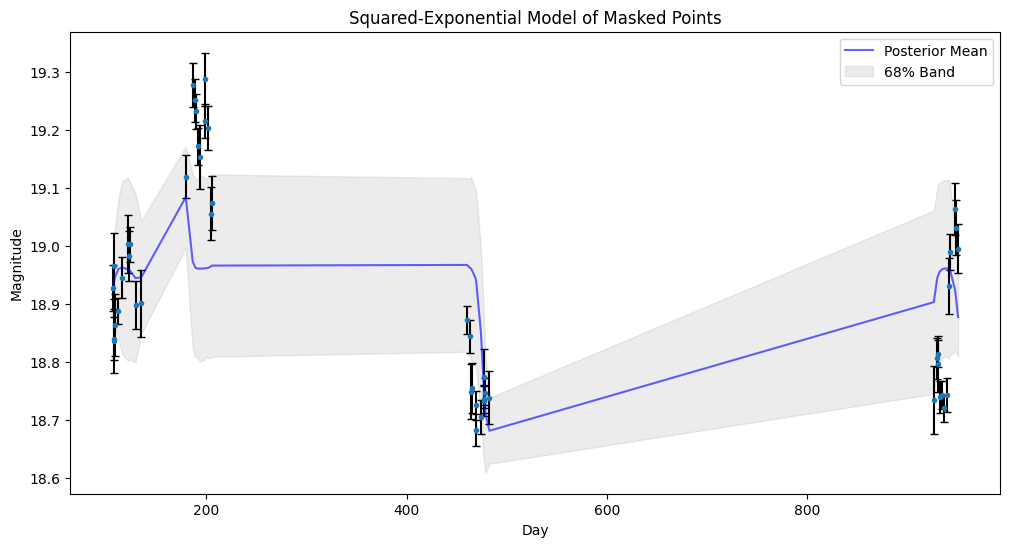

In [257]:
plt.figure(figsize = (12, 6)) 
plt.errorbar(t[rand_mask], y[rand_mask], yerr = e[rand_mask], fmt = '.', ecolor = 'black', capsize = 3)
plt.plot(t[rand_mask], mu_pred_se, color = 'blue', alpha = .6, label = 'Posterior Mean')
plt.fill_between(t[rand_mask], lower_se, upper_se, alpha = 0.15, color = 'grey', label = '68% Band')

plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.title('Squared-Exponential Model of Masked Points')

plt.legend()

In [254]:
inside2 = ((lower_se < y[rand_mask]) & (y[rand_mask] < upper_se))
fraction_inside2 = np.mean(inside2)

print(f'The fraction inside is: {fraction_inside2}')

The fraction inside is: 0.5


In [255]:
y_hat_hold2 = mu_pred_se

R2_esqrd = 1 - np.sum((y_hold - y_hat_hold2)**2) / np.sum((y_hold - y_mean)**2)

print(f'R^2 is: {R2_esqrd:.3f}')

R^2 is: 0.224


In [256]:
print(f'The number held out is: {len(y_hold)}')

The number held out is: 48


**FINAL ANSWER:** 
*sigma = .193 +(0.093) or - (0.035) mag, tau = 56.134 +(72.614) or -(19.619) d, T/tau = 17.186, the exponential kernal beats the squared exponential by delta ln(L) = 23; .625 of 48 held-out points are inside the 68% band.*

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


p_value: .1

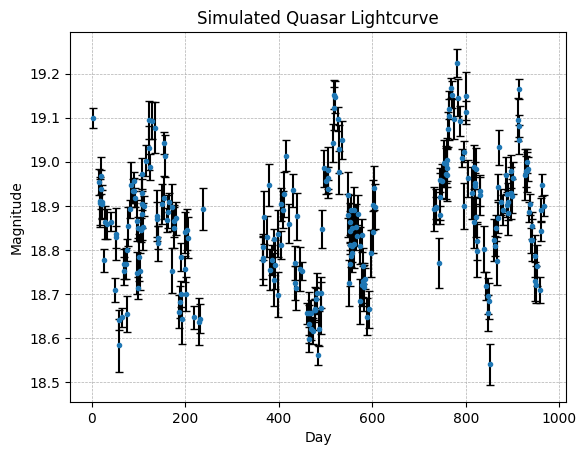

In [376]:
# Part 3: your work here

mu_sim = results[idx][0]
sigma_sim = np.exp(results[idx][1])
tau_sim = np.exp(results[idx][2])

dt_sim = np.abs(t[:, None] - t[None, :])
K_sim = (sigma_sim**2 * np.exp(-dt_sim/tau_sim))
L = np.linalg.cholesky(K_sim)
z = rng.normal(0, 1, len(t))
signal = mu_sim + L @ z
noise = rng.normal(0, e)

y_sim = signal + noise

plt.errorbar(t, y_sim, yerr = e, fmt = '.', ecolor = 'black', capsize = 3)
plt.title('Simulated Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)

In [377]:
power_lst = []
for i in range(5000):
    mu_sim = results[idx][0]
    sigma_sim = np.exp(results[idx][1])
    tau_sim = np.exp(results[idx][2])

    dt_sim = np.abs(t[:, None] - t[None, :])
    K_sim = (sigma_sim**2 * np.exp(-dt_sim/tau_sim))
    L = np.linalg.cholesky(K_sim)
    z = rng.normal(0, 1, len(t))
    signal = mu_sim + L @ z
    noise = rng.normal(0, e)

    y_sim = signal + noise

    ls2 = LombScargle(t, y_sim, dy = e)
    frequency2, power2 = ls2.autopower(minimum_frequency = minfreq, maximum_frequency = maxfreq, samples_per_peak = 10)
    lgst = np.argmax(power2)
    power_lst.append(power2[lgst])

In [378]:
power_lst = np.array(power_lst)
power_mask = (power[peak_indices][true_peak + 1] <= power_lst)

print(f'p_value: {len(power_lst[power_mask]) / len(power_lst)}')

p_value: 0.8902


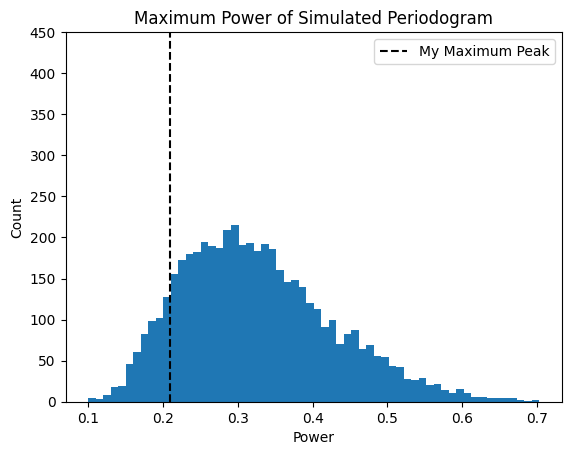

In [379]:
plt.hist(power_lst, bins = 60)
plt.title('Maximum Power of Simulated Periodogram')
plt.xlabel('Power')
plt.ylabel('Count')

plt.vlines(power[peak_indices][true_peak + 1], ymin = 0, ymax = 500, color = 'black', linestyle = '--', label = 'My Maximum Peak')

plt.ylim([0, 450])
plt.legend()

In [312]:
flsalrm = ls.false_alarm_probability(power[peak_indices][true_peak + 1])
print(flsalrm)

6.540762253050354e-10


This value is significantly larger than Astropy's false alarm function. This is as the False alarm function assumes there is no periodic structure in the data. However, this data has many sources of potential periodicity such as when the data was sampled or the seasonal gap structure. As there are periodic structures in the data, the maximally determined power needs to be compared against the periodic structures across multiple iterations.

In [314]:
med_sigma
med_tau
med_mu

np.float64(18.94960787897818)

In [327]:
Periods = np.linspace(20, T/2, 1000)

C_P = (med_sigma**2 * np.exp(-dt3/med_tau) + np.diag(e**2))
Cinv = cho_solve(cho_factor(C_P), np.eye(len(t)) )

chi_lst = []

X0 = np.ones((len(t), 1))
theta0 = (np.linalg.inv(X0.T @ Cinv @ X0) @ (X0.T @ Cinv @ y))
res0 = y - X0 @ theta0
chi2_0 = (res0.T @ Cinv @ res0)

for P in Periods:

    X = np.column_stack([np.ones(len(t)), np.cos(2*np.pi*t/P), np.sin(2*np.pi*t/P)])
    theta = (np.linalg.inv(X.T @ Cinv @ X) @ (X.T @ Cinv @ y))
    res = y - X @ theta
    chi2 = (res.T @ Cinv @ res)

    chi_lst.append(chi2_0 - chi2)

In [334]:
chi_lst = np.array(chi_lst)
max_P = Periods[np.argmax(chi_lst)]

print(f'Maximum Chi2: {np.max(chi_lst):.3f}')
print(f'Period of Maximum Chi2: {max_P:.3f}')

Maximum Chi2: 10.209
Period of Maximum Chi2: 51.009


In [347]:
P_sim = np.linspace(20, T/2, 100)
delta_chi2_lst = []
for i in range(5000):

    z = rng.normal(0, 1, len(t))
    signal = mu_sim + L @ z
    noise = rng.normal(0, e)

    y_sim2 = signal + noise 

    tmp_chi_lst = []

    X0 = np.ones((len(t), 1))
    theta0 = (np.linalg.inv(X0.T @ Cinv @ X0) @ (X0.T @ Cinv @ y_sim2))
    res0 = y_sim2 - X0 @ theta0
    chi2_0 = (res0.T @ Cinv @ res0)

    for P in P_sim:

        X = np.column_stack([np.ones(len(t)), np.cos(2*np.pi*t/P), np.sin(2*np.pi*t/P)])
        theta = (np.linalg.inv(X.T @ Cinv @ X) @ (X.T @ Cinv @ y_sim2))
        res = y_sim2 - X @ theta
        chi2 = (res.T @ Cinv @ res)

        tmp_chi_lst.append(chi2_0 - chi2)

    delta_chi2_lst.append(max(tmp_chi_lst))

In [350]:
delta_chi2_lst = np.array(delta_chi2_lst)

chi_mask = ( np.max(chi_lst) < delta_chi2_lst)
print(f'p_value: {len(delta_chi2_lst[chi_mask]) / len(delta_chi2_lst)}')

p_value: 0.1336


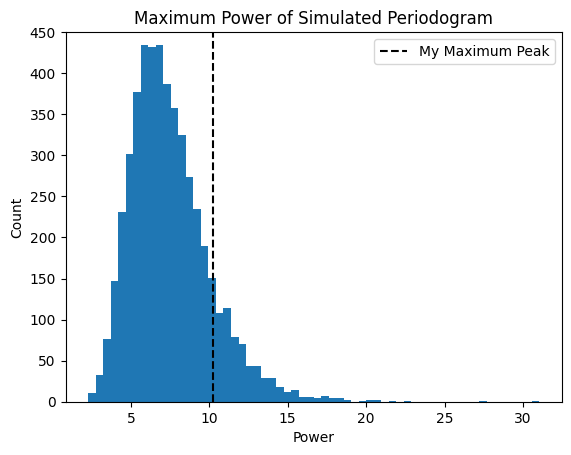

In [352]:
plt.hist(delta_chi2_lst, bins = 60)
plt.title('Maximum delta_chi2 of Simulated data')
plt.xlabel('delta_chi2')
plt.ylabel('Count')

plt.vlines(np.max(chi_lst), ymin = 0, ymax = 500, color = 'black', linestyle = '--', label = 'My Maximum Peak')

plt.ylim([0, 450])
plt.legend()

**ANSWER (the decision rule first, then the verdict):**

*There is no evidence for a periodic signal as the p_value is greater than .1. For there to be evidecnce, the maximal deltaChi2 value would need to be greater than 99.9% of the data. As it happens, it is within the 13th percentile. The team should NOT announce a binary candidate.*

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


In [264]:
# Part 4: your work here
#False Alarm Probability
#Models it as a Squared Exponential
#Handles Errors Wrong

1) The Ai confidently reports:

In [353]:
freq = np.linspace(1. / (T / 2.), 1. / 20., 6000)
ls = LombScargle(t, y, e)
power = ls.power(freq)
k = np.argmax(power)
P_best, p_best = 1. / freq[k], power[k]
fap = ls.false_alarm_probability(p_best, minimum_frequency=freq[0], maximum_frequency=freq[-1])
print(f"false-alarm probability {fap:.1e}")

false-alarm probability 3.4e-25


Claiming that the probability is "many orders of magnitude below any conventional threshold, so the periodicity is highly significant." This reasoning is incorrect. The false alarm probability uses the assumption that there are no periodic structures within the dataset. However, this is not the case for our current dataset (there is periodic gaps). The proper handling of this is to run a simulation (as in part 2) to get the strength of the maximal peak in context with how strong of a periodic signal like that appears in your data. 

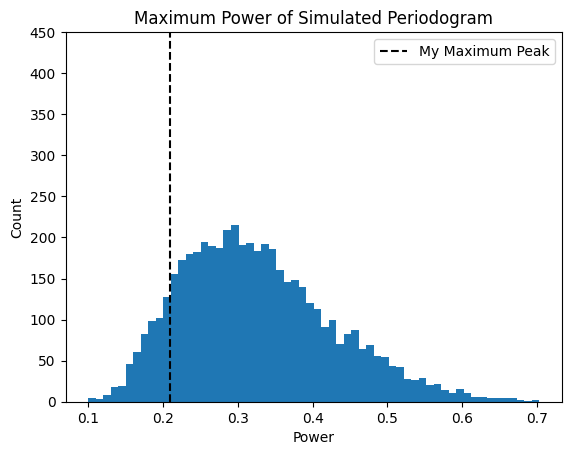

In [380]:
plt.hist(power_lst, bins = 60)
plt.title('Maximum Power of Simulated Periodogram')
plt.xlabel('Power')
plt.ylabel('Count')

plt.vlines(power[peak_indices][true_peak + 1], ymin = 0, ymax = 500, color = 'black', linestyle = '--', label = 'My Maximum Peak')

plt.ylim([0, 450])
plt.legend()

By simulating a host of lightcurves, we can pick out how often a periodic signal like this occurs in the data given the uncertainties. This turns the "highly significant" detection into a false alarm.

2) The ai uses a squared exponential to model the data

The Ai claims that: "Quasar variability on these time scales is smooth, so we model it with a squared-exponential kernel, $k(\Delta t) = \sigma^2 \exp(-\Delta t^2 / 2\ell^2)$, which is infinitely differentiable and the standard default choice. We maximize the marginal likelihood over the mean, amplitude $\sigma$ and length scale $\ell$."

In [383]:
def nll(p, tt=t, yy=y, ee=e):
    mu, ls_, ll = p
    K = np.exp(2 * ls_) * np.exp(-0.5 * ((tt[:, None] - tt[None, :]) / np.exp(ll)) ** 2) + np.diag(ee ** 2)
    try:
        c = cho_factor(K, lower=True)
    except np.linalg.LinAlgError:
        return 1e10
    r = yy - mu
    return 0.5 * r @ cho_solve(c, r) + np.log(np.diag(c[0])).sum() + 0.5 * yy.size * np.log(2 * np.pi)

p0 = [y.mean(), np.log(y.std()), np.log(30.)]
res = minimize(nll, p0, method='Nelder-Mead', options=dict(xatol=1e-4, fatol=1e-6, maxiter=1500))
mu_hat, sig_hat, ell_hat = res.x[0], np.exp(res.x[1]), np.exp(res.x[2])

print(mu_hat, sig_hat, ell_hat)

18.960936015651193 0.15060505167513902 5.768912269515773


In [388]:
res.x

array([18.96093602, -1.89309442,  1.75248355])

In [391]:
log_likelihood_se(res.x, t, y, e)

np.float64(287.5679505066213)

The Ai's model found a Likelihood of ~ 288. As discovered in part 2, there is a difference in the max likelihood of the squared eponential model and the DRW model of about ~23. This means that the model the Ai is using does not reflect the true errors of the data.

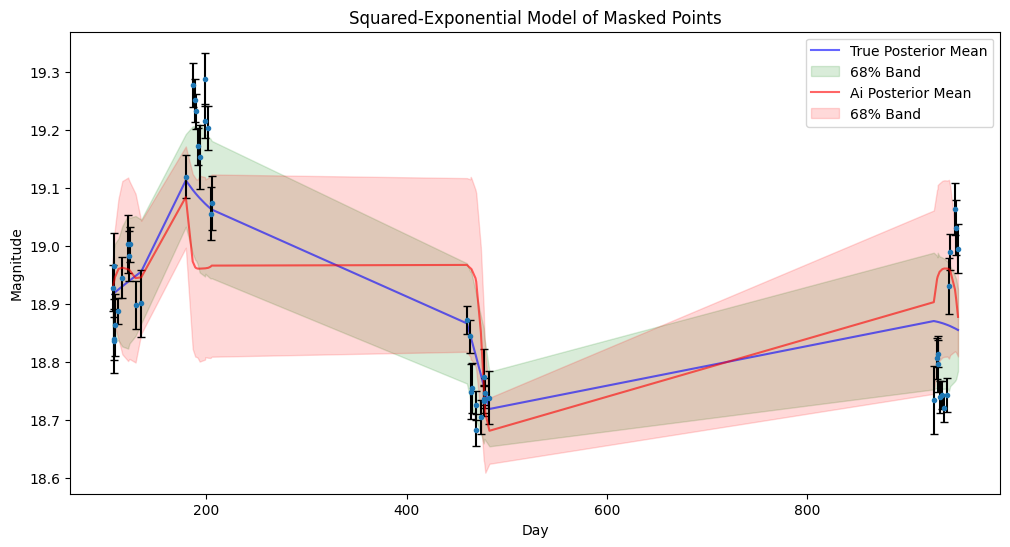

In [396]:
plt.figure(figsize = (12, 6)) 

plt.plot(t[rand_mask], mu_pred3, color = 'blue', alpha = .6, label = 'True Posterior Mean')
plt.fill_between(t[rand_mask], lower3, upper3, alpha = 0.15, color = 'green', label = '68% Band')

plt.errorbar(t[rand_mask], y[rand_mask], yerr = e[rand_mask], fmt = '.', ecolor = 'black', capsize = 3)
plt.plot(t[rand_mask], mu_pred_se, color = 'red', alpha = .6, label = 'Ai Posterior Mean')
plt.fill_between(t[rand_mask], lower_se, upper_se, alpha = 0.15, color = 'red', label = '68% Band')

plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.title('Squared-Exponential Model of Masked Points')

plt.legend()

In [401]:
print(f'DRW acceptance: {R2:.3f}')
print(f'Squared-Exponential acceptance: {R2_esqrd:.3f}')

DRW acceptance: 0.698
Squared-Exponential acceptance: 0.224


As I found earlier, using a squared exponetial drops the R2 value to 1/3 of that of the DRW. This indicates that the model is not covering the new points as well as the DRW model. 

3) The Ai calcualtes the uncertainties incorrectly.

In its model, the Ai uses the Hessian to calculte its uncertainties:

In [403]:
# error on ell from the curvature of the likelihood at the maximum
h = 0.05
f0 = lambda dl: nll([res.x[0], res.x[1], res.x[2] + dl])
curv = (f0(h) - 2 * f0(0.) + f0(-h)) / h ** 2
ell_err = ell_hat / np.sqrt(curv)
print(f"MAP: sigma = {sig_hat:.3f} mag, ell = {ell_hat:.1f} +/- {ell_err:.1f} d, ln L = {-res.fun:.1f}")

MAP: sigma = 0.151 mag, ell = 5.8 +/- 0.4 d, ln L = 287.6


These errors are symmetric about the medians. However, as I found in part two, the errors are non-symmetric:

(0.0, 1000.0)

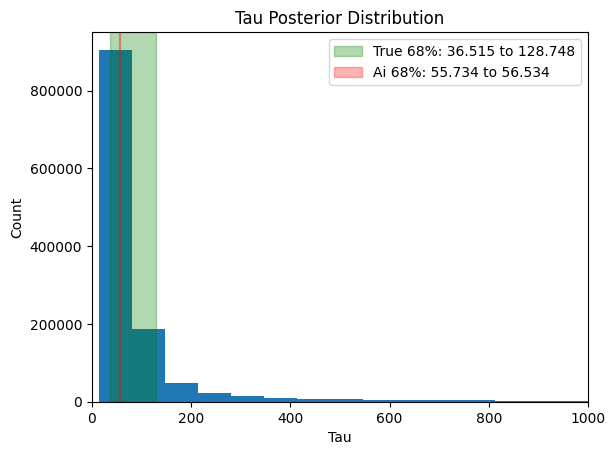

In [413]:
plt.figure(2)
plt.hist(MCMCTau, bins = 60)
plt.title('Tau Posterior Distribution')
plt.xlabel('Tau')
plt.ylabel('Count')

lo_tau, med_tau, hi_tau = np.percentile(MCMCTau, [16, 50, 84])
plt.axvspan(lo_tau, hi_tau, color = 'green', alpha = .3, label = f'True 68%: {lo_tau:.3f} to {hi_tau:.3f}')
plt.axvspan(med_tau - 2 * .4, med_tau + 2 * .4, color = 'red', alpha = .3, label = f'Ai 68%: {(med_tau - .4):.3f} to {(med_tau + .4):.3f}')

plt.legend()

plt.xlim([0, 1000])

The Ai's errors become much smaller than they should be as it doesn't take the true middle 68% into account.  

**REFEREE REPORT:**

*The Ai made mistakes in:
1) using Astropy false Alarm for a detection
2) using a squared eponential model
3) using symmetric error bars*

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [415]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('../../labs/07/data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18aafzvom: 687 g-band detections from the live API
ZTF18aafzvom: MJD 58495.3 to 61340.5 (7.8 yr); the last detection is MJD 61340.5; today is MJD 61341


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


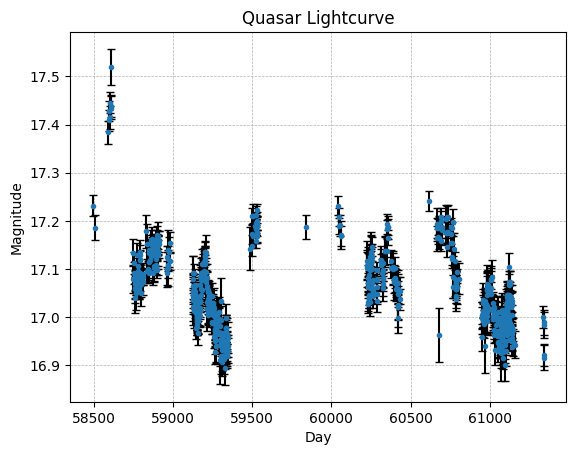

In [418]:
# Part 5: your work here

plt.errorbar(mjd, mag, yerr = merr, fmt = '.', ecolor = 'black', capsize = 3)
plt.title('Quasar Lightcurve')
plt.xlabel('Day')
plt.ylabel('Magnitude')
plt.grid(linestyle = '--', linewidth = 0.5)

In [421]:
min_t = np.min(mjd)
max_t = np.max(mjd)
T_new =  max_t - min_t
t_new = mjd - min_t

In [459]:
start_new = []

for i in range(10):
    for j in range(10):
        start_new.append([np.mean(mag), np.log(sigma_start[i]), np.log(tau_start[j]) ] )

results_new = []
liklihoods_new = []

for s in start_new:

    result = minimize(
        lambda theta: -log_likelihood(theta, t_new, mag, merr), s)

    results_new.append(result.x)
    liklihoods_new.append(-result.fun)

In [460]:
liklihoods_new = np.array(liklihoods_new)
idx_new = np.argmax(liklihoods_new)

print(liklihoods_new[idx_new])
print(results_new[idx_new])

1446.2217814265491
[17.11097562 -2.22063976  5.86822231]


In [461]:
mu_new = results_new[idx_new][0]
sigma_new = np.exp(results_new[idx_new][1])
tau_new = np.exp(results_new[idx_new][2])

In [462]:
Periods_new = np.linspace(20, T_new/2, 1000)

C_P = (sigma_new**2 * np.exp(-np.abs(t_new[:, None] - t_new[None, :])/tau_new) + np.diag(merr**2))
Cinv = cho_solve(cho_factor(C_P), np.eye(len(t_new)) )

chi_lst = []

X0 = np.ones((len(t_new), 1))
theta0 = (np.linalg.inv(X0.T @ Cinv @ X0) @ (X0.T @ Cinv @ mag))
res0 = mag - X0 @ theta0
chi2_0 = (res0.T @ Cinv @ res0)

for P in Periods_new:

    X = np.column_stack([np.ones(len(t_new)), np.cos(2*np.pi*t_new/P), np.sin(2*np.pi*t_new/P)])
    theta = (np.linalg.inv(X.T @ Cinv @ X) @ (X.T @ Cinv @ mag))
    res = mag - X @ theta
    chi2 = (res.T @ Cinv @ res)

    chi_lst.append(chi2_0 - chi2)

In [463]:
chi_lst = np.array(chi_lst)
chi_lst_idx = np.argmax(chi_lst)
max_P = Periods_new[chi_lst_idx]

print(f'Maximum Chi2: {np.max(chi_lst):.3f}')
print(f'Period of Maximum Chi2: {max_P}')

Maximum Chi2: 14.439
Period of Maximum Chi2: 290.97463874856095


In [464]:
K_new = (sigma_new**2 * np.exp(-np.abs(t_new[:, None] - t_new[None, :])/tau_new))
L_new = np.linalg.cholesky(K_new)
z = rng.normal(0, 1, len(t_new))

LinAlgError: Matrix is not positive definite

In [ ]:
P_sim = np.linspace(20, T_new/2, 100)
delta_chi2_lst = []
for i in range(5000):

    z = rng.normal(0, 1, len(t_new))
    signal = mu_new + L_new @ z_new
    noise = rng.normal(0, merr)

    y_sim2 = signal + noise 

    tmp_chi_lst = []

    X0 = np.ones((len(t_new), 1))
    theta0 = (np.linalg.inv(X0.T @ Cinv @ X0) @ (X0.T @ Cinv @ y_sim2))
    res0 = y_sim2 - X0 @ theta0
    chi2_0 = (res0.T @ Cinv @ res0)

    for P in P_sim:

        X = np.column_stack([np.ones(len(t_new)), np.cos(2*np.pi*t/P), np.sin(2*np.pi*t/P)])
        theta = (np.linalg.inv(X.T @ Cinv @ X) @ (X.T @ Cinv @ y_sim2))
        res = y_sim2 - X @ theta
        chi2 = (res.T @ Cinv @ res)

        tmp_chi_lst.append(chi2_0 - chi2)

    delta_chi2_lst.append(max(tmp_chi_lst))

In [ ]:
delta_chi2_lst = np.array(delta_chi2_lst)

chi_mask = ( np.max(chi_lst) < delta_chi2_lst)
print(f'p_value: {len(delta_chi2_lst[chi_mask]) / len(delta_chi2_lst)}')

In [ ]:
plt.hist(delta_chi2_lst, bins = 60)
plt.title('Maximum delta_chi2 of Simulated data')
plt.xlabel('delta_chi2')
plt.ylabel('Count')

plt.vlines(np.max(chi_lst), ymin = 0, ymax = 500, color = 'black', linestyle = '--', label = 'My Maximum Peak')

plt.ylim([0, 450])
plt.legend()

**ANSWER (the criterion first, then the result):**

*your answer goes here*

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

*I used Copilot as a debugger and to help generate the code in this document. I used it to help me learn how to generate the DRW and also used it to help structure and code the period simulation.*

**REFLECTION:**

*The Ai got confused initially and thought I wanted a chi2 instead of R2 outprint. Due to this, it told me that I should report the sum of (y - mody)^2/sigma instead of 1 - (y - mody)^2 / (y - muy)^2. If I hadn't noticed this and double checked which values I actually needed to get, I would've ended up with the wrong value in my report.*

**VERIFICATION PLAN:**

*To verify my work. I generated a synthetic light curve. *